Original counts:
{'010': 37, '000': 349, '111': 375, '110': 56, '001': 41, '011': 46, '101': 47, '100': 49}

Mitigated counts:
{'000': 477, '001': 0, '010': 0, '011': 11, '100': 7, '101': 0, '110': 16, '111': 489}


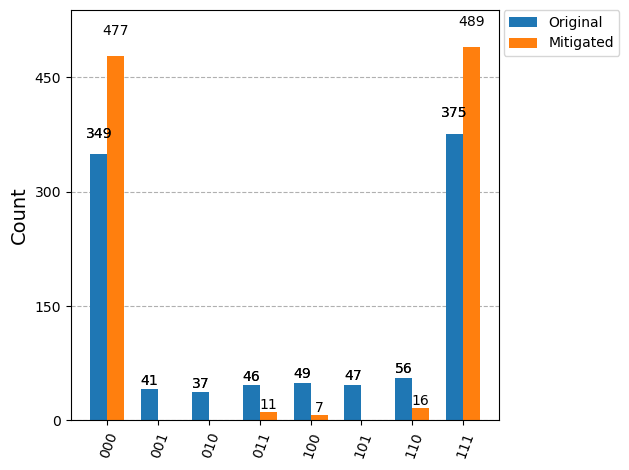

In [2]:
#%pip install qiskit qiskit-aer matplotlib
# Step 1: Import required libraries
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
from qiskit.visualization import plot_histogram

# Step 2: Create a noise model
noise_model = NoiseModel()

# Define measurement error
readout_error = ReadoutError([
    [0.90, 0.10],
    [0.10, 0.90]
])

# Apply measurement error to all qubits
noise_model.add_all_qubit_readout_error(readout_error)

# Step 3: Define the quantum circuit
qc = QuantumCircuit(3, 3)

# Step 4: Apply quantum gates
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)

# Step 5: Measure the qubits
qc.measure([0, 1, 2], [0, 1, 2])

# Step 6: Create the noisy simulator
backend = AerSimulator(noise_model=noise_model)

# Step 7: Transpile the circuit
transpiled_qc = transpile(qc, backend)

# Step 8: Execute the noisy circuit
job = backend.run(transpiled_qc, shots=1000)
result = job.result()

# Get original measurement counts
counts = result.get_counts()

print("Original counts:")
print(counts)

# Step 9: Generate calibration circuits
cal_circuits = []

for state in range(8):
    cal_qc = QuantumCircuit(3, 3)

    # Prepare each computational basis state
    for qubit in range(3):
        if (state >> qubit) & 1:
            cal_qc.x(qubit)

    cal_qc.measure([0, 1, 2], [0, 1, 2])
    cal_circuits.append(cal_qc)

# Step 10: Run calibration circuits
transpiled_cal = transpile(cal_circuits, backend)

cal_job = backend.run(transpiled_cal, shots=1000)
cal_result = cal_job.result()

# Step 11: Construct the calibration matrix
cal_matrix = np.zeros((8, 8))

for prepared_state in range(8):
    cal_counts = cal_result.get_counts(prepared_state)
    total_shots = sum(cal_counts.values())

    for measured_state, frequency in cal_counts.items():
        measured_index = int(measured_state.replace(" ", ""), 2)
        cal_matrix[measured_index, prepared_state] = (
            frequency / total_shots
        )

# Step 12: Perform measurement error mitigation
observed = np.zeros(8)
total_shots = sum(counts.values())

for state, frequency in counts.items():
    index = int(state.replace(" ", ""), 2)
    observed[index] = frequency / total_shots

# Apply inverse calibration matrix
mitigated = np.linalg.solve(cal_matrix, observed)

# Remove small negative probabilities and normalize
mitigated = np.clip(mitigated, 0, None)
mitigated = mitigated / mitigated.sum()

# Convert probabilities into corrected counts
mitigated_counts = {
    format(i, "03b"): int(round(prob * total_shots))
    for i, prob in enumerate(mitigated)
}

print("\nMitigated counts:")
print(mitigated_counts)

# Step 13: Plot original and mitigated results
plot_histogram(
    [counts, mitigated_counts],
    legend=["Original", "Mitigated"]
)
